In [5]:
import io
import os
import pandas as pd
import paramiko

import matplotlib.pyplot as plt
df=pd.read_pickle("Sample_Feb.pkl")



In [6]:
ts = pd.to_datetime(df["Timestamp (end of interval)"])

df_deg = df[
    (ts >= "2025-02-12 18:00:00") &
    (ts <= "2025-02-13 06:00:00")
].copy()

In [7]:
direction_cols = [col for col in df_deg.columns if "Direction" in col]
keep_cols = ["Timestamp (end of interval)"] + direction_cols

df_deg = df_deg[keep_cols].copy()
df_deg

,Timestamp (end of interval),40m Wind Direction (ｰ),60m Wind Direction (ｰ),80m Wind Direction (ｰ),100m Wind Direction (ｰ),120m Wind Direction (ｰ),140m Wind Direction (ｰ),160m Wind Direction (ｰ),180m Wind Direction (ｰ),200m Wind Direction (ｰ),220m Wind Direction (ｰ),240m Wind Direction (ｰ),260m Wind Direction (ｰ),280m Wind Direction (ｰ),300m Wind Direction (ｰ)
1677,2025-02-12 18:00:00,205.07,185.44,178.94,175.16,173.59,169.90,163.58,158.12,156.54,154.32,154.18,153.92,154.10,154.43
1678,2025-02-12 18:10:00,238.95,229.25,224.82,211.87,195.55,183.31,174.44,168.47,163.40,158.77,156.88,156.66,157.09,156.88
1679,2025-02-12 18:20:00,258.02,239.00,211.79,194.56,185.21,176.86,171.24,168.10,163.58,160.18,158.34,157.12,157.11,155.49
1680,2025-02-12 18:30:00,261.14,244.01,213.40,190.24,178.15,170.49,165.89,163.01,160.59,157.38,156.55,155.23,153.71,152.80
1681,2025-02-12 18:40:00,241.83,225.66,195.92,174.73,164.39,158.66,154.60,151.08,148.25,147.30,147.18,146.74,145.77,145.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745,2025-02-13 05:20:00,224.44,224.95,224.81,225.30,225.96,226.64,226.66,227.11,227.07,227.63,228.10,228.48,228.65,229.35
1746,2025-02-13 05:30:00,226.93,227.69,227.85,228.54,229.00,229.67,230.06,230.48,230.47,230.25,230.47,230.67,230.79,230.99
1747,2025-02-13 05:40:00,230.82,231.19,232.03,232.16,232.44,233.42,233.78,234.04,233.74,233.59,233.80,234.33,233.74,233.48
1748,2025-02-13 05:50:00,231.97,231.84,232.50,232.95,233.42,233.36,233.90,234.56,235.03,234.93,234.85,235.21,235.30,235.89


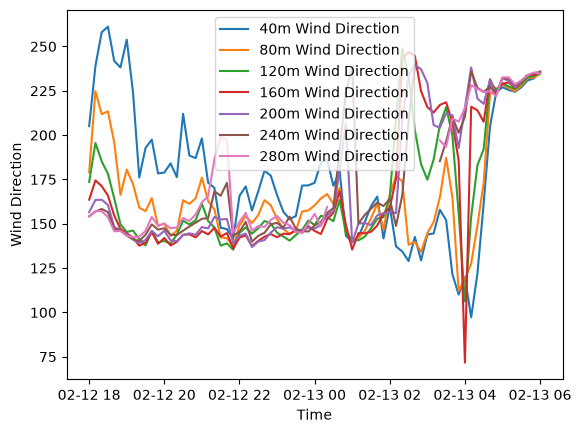

In [8]:
for n in [40,  80,120,  160,  200, 240,  280]:
    plt.plot(df_deg["Timestamp (end of interval)"], df_deg[f"{n}m Wind Direction (ｰ)"], label=f"{n}m Wind Direction")
    plt.xlabel("Time")
    plt.ylabel("Wind Direction")
    #plt.title(f"{n}m Wind Direction over Time")
    plt.legend()
plt.show()

In [9]:
import re


def normalize_circular_diff(diff):
    return ((diff + 180) % 360) - 180


# 方向データの列を高度順に並べ、各高度ペアごとの veer を追加
# 例: 40-60m Veer, 60-80m Veer, ...
direction_cols = [col for col in df_deg.columns if "Direction" in col]
direction_cols = sorted(direction_cols, key=lambda c: int(re.search(r"(\d+)m", c).group(1)))

for i in range(len(direction_cols) - 1):
    left_col = direction_cols[i]
    right_col = direction_cols[i + 1]
    left_h = re.search(r"(\d+)m", left_col).group(1)
    right_h = re.search(r"(\d+)m", right_col).group(1)

    veer_name = f"{left_h}-{right_h}m Veer"
    diff = normalize_circular_diff(df_deg[left_col] - df_deg[right_col])
    df_deg.insert(df_deg.columns.get_loc(left_col) + 1, veer_name, diff)

# 生成結果の確認
df_deg.head()

,Timestamp (end of interval),40m Wind Direction (ｰ),40-60m Veer,60m Wind Direction (ｰ),60-80m Veer,80m Wind Direction (ｰ),80-100m Veer,100m Wind Direction (ｰ),100-120m Veer,120m Wind Direction (ｰ),...,200-220m Veer,220m Wind Direction (ｰ),220-240m Veer,240m Wind Direction (ｰ),240-260m Veer,260m Wind Direction (ｰ),260-280m Veer,280m Wind Direction (ｰ),280-300m Veer,300m Wind Direction (ｰ)
1677,2025-02-12 18:00:00,205.07,19.63,185.44,6.50,178.94,3.78,175.16,1.57,173.59,...,2.22,154.32,0.14,154.18,0.26,153.92,-0.18,154.10,-0.33,154.43
1678,2025-02-12 18:10:00,238.95,9.70,229.25,4.43,224.82,12.95,211.87,16.32,195.55,...,4.63,158.77,1.89,156.88,0.22,156.66,-0.43,157.09,0.21,156.88
1679,2025-02-12 18:20:00,258.02,19.02,239.00,27.21,211.79,17.23,194.56,9.35,185.21,...,3.40,160.18,1.84,158.34,1.22,157.12,0.01,157.11,1.62,155.49
1680,2025-02-12 18:30:00,261.14,17.13,244.01,30.61,213.40,23.16,190.24,12.09,178.15,...,3.21,157.38,0.83,156.55,1.32,155.23,1.52,153.71,0.91,152.80
1681,2025-02-12 18:40:00,241.83,16.17,225.66,29.74,195.92,21.19,174.73,10.34,164.39,...,0.95,147.30,0.12,147.18,0.44,146.74,0.97,145.77,-0.21,145.98


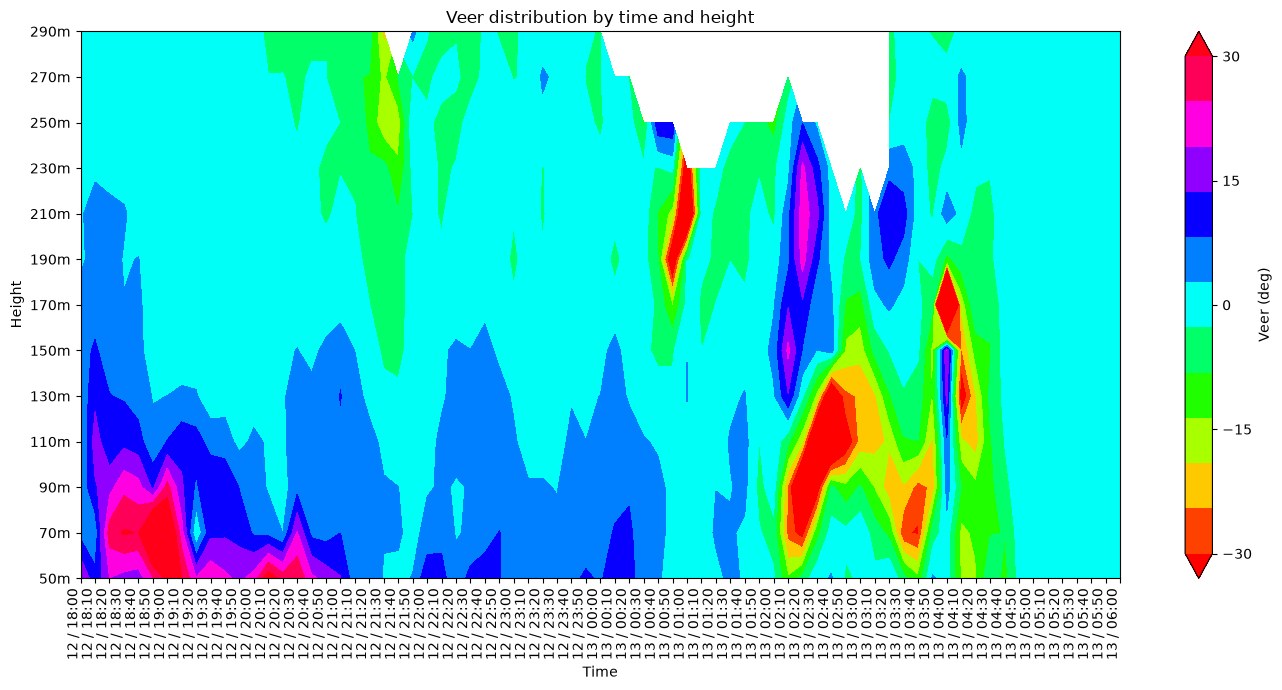

In [15]:
import re
import numpy as np

# Veer の列を高度順に並べる
veer_cols = sorted(
    [c for c in df_deg.columns if "Veer" in c],
    key=lambda c: tuple(map(int, re.findall(r"\d+", c)[:2])),
)

veer_df = df_deg.set_index("Timestamp (end of interval)")[veer_cols].copy()

# 縦軸は各層の中心高度（40-60m → 50m, 60-80m → 70m）
heights = []
for c in veer_cols:
    nums = list(map(int, re.findall(r"\d+", c)))
    heights.append((nums[0] + nums[1]) / 2)

fig, ax = plt.subplots(figsize=(14, 7))
mesh = ax.contourf(
    np.arange(len(veer_df.index)),
    heights,
    veer_df.T.to_numpy(),
    levels=np.linspace(-30, 30, 12),
    cmap="hsv",
    extend="both",
)

ax.set_yticks(heights)
ax.set_yticklabels([f"{int(h)}m" for h in heights])
ax.set_xticks(np.arange(len(veer_df.index)))
ax.set_xticklabels(veer_df.index.strftime("%d / %H:%M"), rotation=90, ha="right")
ax.set_xlabel("Time")
ax.set_ylabel("Height")
ax.set_title("Veer distribution by time and height")

cbar = fig.colorbar(mesh, ax=ax, label="Veer (deg)")
cbar.set_ticks(np.arange(-30, 31, 15))
plt.tight_layout()
plt.show()


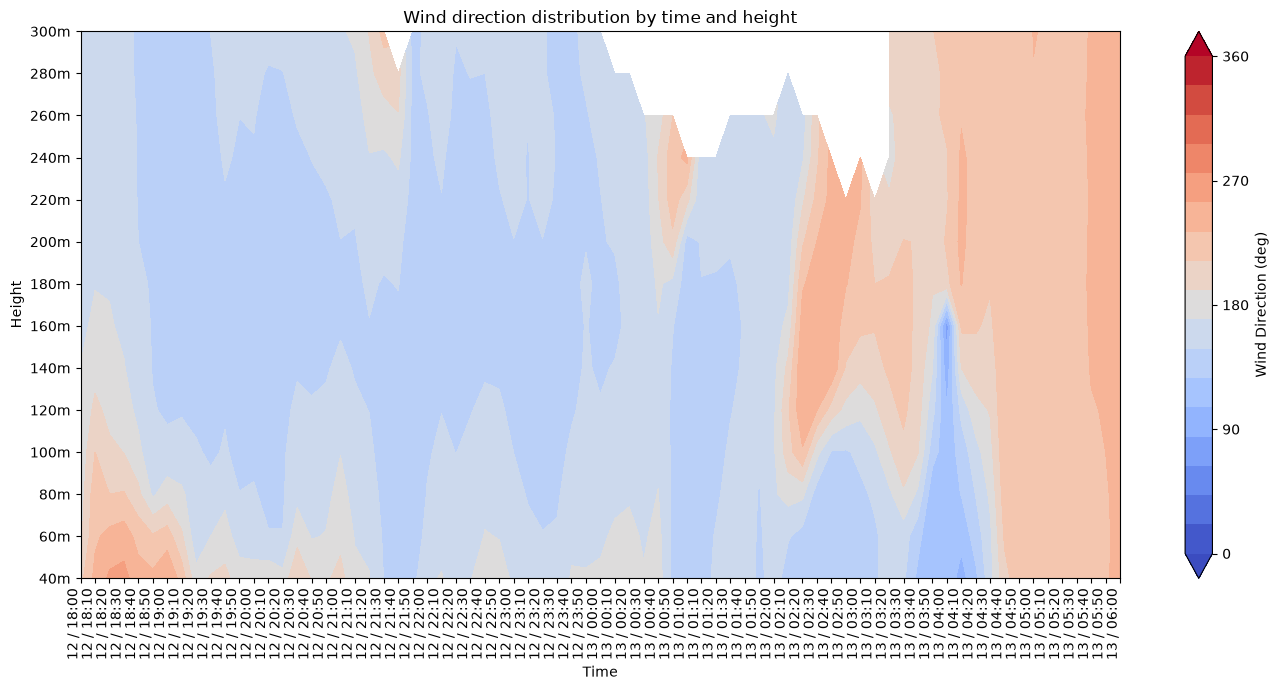

In [16]:
import re
import numpy as np

# 風向の列を高度順に並べる
wind_dir_cols = sorted(
    [c for c in df_deg.columns if "Wind Direction" in c],
    key=lambda c: int(re.search(r"(\d+)m", c).group(1)),
)

# 0–360° の範囲に揃える
wind_dir_df = df_deg.set_index("Timestamp (end of interval)")[wind_dir_cols].copy()
wind_dir_df = np.mod(wind_dir_df, 360)

# 縦軸に使う高度（40, 60, 80, ...）
heights = [int(re.search(r"(\d+)m", c).group(1)) for c in wind_dir_cols]

fig, ax = plt.subplots(figsize=(14, 7))
mesh = ax.contourf(
    np.arange(len(wind_dir_df.index)),
    heights,
    wind_dir_df.T.to_numpy(),
    levels=np.linspace(0, 360, 18),
    cmap="coolwarm",
    extend="both",
)

ax.set_yticks(heights)
ax.set_yticklabels([f"{h}m" for h in heights])
ax.set_xticks(np.arange(len(wind_dir_df.index)))
ax.set_xticklabels(wind_dir_df.index.strftime("%d / %H:%M"), rotation=90, ha="right")
ax.set_xlabel("Time")
ax.set_ylabel("Height")
ax.set_title("Wind direction distribution by time and height")

cbar = fig.colorbar(mesh, ax=ax, label="Wind Direction (deg)")
cbar.set_ticks(np.arange(0, 361, 90))
plt.tight_layout()
plt.show()
